# Auditing AI-text detectors for students in Aotearoa

**AIML430 capstone. Josh Lafrentz (300652648)**

**Research question:** How reliable and fair are AI-text detectors for students in Aotearoa, and should NZ universities use them in academic misconduct decisions?

This notebook produces every result and figure in the report from the detector scores in `results/scores/` (created with `src/score.py`). All human writing predates ChatGPT (30 Nov 2022).

| Group | Source | n |
|---|---|---|
| Native English / English learners | PERSUADE 2.0 essays (US, grades 6-12, 2010-2020), matched on prompt and length | 200 / 200 |
| Calibration (thresholds only) | Further native PERSUADE essays, disjoint from the above | 1,000 |
| NZ English with / without te reo | .nz web pages crawled 2013-2020, same outlets, length-matched | 200 / 200 |
| Te reo Māori | Whakaata Māori news and Salient; Te Ara encyclopedia | 200 / 200 |
| AI texts | Claude: written from the prompt, paraphrased, grammar-fixed | 80 |

In [1]:
# This cell loads the libraries and every score table, and adds an "AI score"
# for each detector where higher always means "looks more machine-written".
import numpy as np, pandas as pd, matplotlib.pyplot as plt, statsmodels.formula.api as smf
from scipy import stats
from sklearn.metrics import roc_auc_score
from statsmodels.stats.proportion import proportion_confint

S = {k: pd.read_csv(f"../results/scores/scores_{k}.csv", dtype={"essay_id": str, "source_essay_id": str})
     for k in ["calibration_native", "human_persuade", "nz", "frontier", "reo_human", "reo_frontier"]}
for d in S.values():
    d["ai_fast_detect_gpt"], d["ai_binoculars"], d["ai_perplexity"] = (
        d.fast_detect_gpt, -d.binoculars, -np.log(d.perplexity))
df = pd.concat([S["human_persuade"], S["nz"], S["frontier"]], ignore_index=True)
DET = {"fast_detect_gpt": "Fast-DetectGPT", "binoculars": "Binoculars", "perplexity": "Perplexity"}
HUMAN = {"native": "Native English (US students)", "esl": "English learners (US students)",
         "nz_web_plain": "NZ English, no te reo", "nz_web_reo": "NZ English with te reo",
         "mi_news": "Te reo Māori (news)", "teara_mi": "Te reo Māori (Te Ara)"}
AI = {"frontier_generate": "AI-written", "frontier_paraphrase_esl": "AI-paraphrased ESL essay",
      "frontier_paraphrase_native": "AI-paraphrased native essay",
      "frontier_polish_esl": "Grammar-fixed ESL essay", "frontier_polish_native": "Grammar-fixed native essay",
      "teara_en_mt": "Machine-translated English (Te Ara)"}
BLUE, ORANGE, AQUA, INK = "#2a78d6", "#eb6834", "#1baf7a", "#52514e"
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "font.size": 9.5,
                     "axes.titleweight": "bold", "axes.titlelocation": "left", "savefig.dpi": 300})

In [2]:
# This function gives a 95% Wilson confidence interval for a proportion, which
# stays sensible for small rates (unlike the usual p ± 1.96 standard errors).
def wilson(k, n):
    return proportion_confint(k, n, method="wilson")

# This function returns the share of each group flagged by each detector at the
# given thresholds, with confidence intervals.
def flag_rates(data, thr, groups):
    rows = []
    for g, label in groups.items():
        sub = data[data.group == g]
        for det, name in DET.items():
            k = int((sub[f"ai_{det}"] > thr[det]).sum())
            rows.append({"group": g, "label": label, "detector": name, "n": len(sub),
                         "flagged": k, "rate": k / len(sub), "ci": wilson(k, len(sub))})
    return pd.DataFrame(rows)

## 1. Thresholds set the way a vendor would

Each threshold is chosen so that 1% or 5% of the **held-out** calibration essays are flagged (Turnitin advertises under 1%). Nothing evaluated below was used to set them.

In [3]:
# This cell sets each detector's threshold at the 99th and 95th percentile of
# its scores on the 1,000 held-out native essays.
thr = {f: {d: float(np.quantile(S["calibration_native"][f"ai_{d}"], 1 - f, method="higher"))
           for d in DET} for f in (0.01, 0.05)}
pd.DataFrame(thr)

,0.01,0.05
fast_detect_gpt,1.736302,0.955597
binoculars,-0.916744,-0.956092
perplexity,-2.078413,-2.309985


## 2. Reliability: how well do the detectors separate human from AI writing?

AUROC is the chance a random AI-written essay scores as more machine-like than a random human text (0.5 = coin flip, 1 = perfect). The second table shows how much AI text is actually caught.

In [4]:
# This cell computes AUROC for each human group against the AI-written essays,
# then the share of each kind of AI-involved text flagged at both thresholds.
ai = df[df.group == "frontier_generate"]
auc = pd.DataFrame({name: {HUMAN[g]: roc_auc_score(
    np.r_[np.zeros((df.group == g).sum()), np.ones(len(ai))],
    np.r_[df.loc[df.group == g, f"ai_{d}"], ai[f"ai_{d}"]]) for g in HUMAN} for d, name in DET.items()})
display(auc.round(3))
pd.concat({f"{f:.0%} threshold": flag_rates(df, thr[f], AI).pivot(index="label", columns="detector",
           values="rate") for f in (0.01, 0.05)}, axis=1).round(3)

,Fast-DetectGPT,Binoculars,Perplexity
Native English (US students),0.750,0.794,0.957
English learners (US students),0.785,0.815,0.978
"NZ English, no te reo",0.704,0.761,0.974
NZ English with te reo,0.704,0.763,0.967
Te reo Māori (news),0.726,0.765,0.980
Te reo Māori (Te Ara),0.647,0.716,0.995


1% threshold                            \
detector                              Binoculars Fast-DetectGPT Perplexity   
label                                                                        
AI-paraphrased ESL essay                   0.000          0.000       0.10   
AI-paraphrased native essay                0.000          0.000       0.00   
AI-written                                 0.233          0.300       0.20   
Grammar-fixed ESL essay                    0.050          0.000       0.00   
Grammar-fixed native essay                 0.200          0.300       0.00   
Machine-translated English (Te Ara)        0.005          0.015       0.02   

                                    5% threshold                            
detector                              Binoculars Fast-DetectGPT Perplexity  
label                                                                       
AI-paraphrased ESL essay                   0.300          0.300       0.30  
AI-paraphrased native essay                0.300          0.300       0.10  
AI-written                                 0.533          0.500       0.60  
Grammar-fixed ESL essay                    0.250          0.150       0.20  
Grammar-fixed native essay                 0.500          0.400       0.40  
Machine-translated English (Te Ara)        0.060          0.065       0.04

## 3. Fairness: who is wrongly flagged?

False positive rates for every human group at the 5% threshold (Figure 1), and one-sided Fisher exact tests of whether English learners, NZ English with te reo, or te reo Māori are flagged more than their comparison group.

detector,Binoculars,Fast-DetectGPT,Perplexity
label,,,
Native English (US students),0.055,0.060,0.035
English learners (US students),0.055,0.055,0.025
"NZ English, no te reo",0.045,0.070,0.025
NZ English with te reo,0.040,0.070,0.035
Te reo Māori (news),0.045,0.045,0.020
Te reo Māori (Te Ara),0.050,0.100,0.005


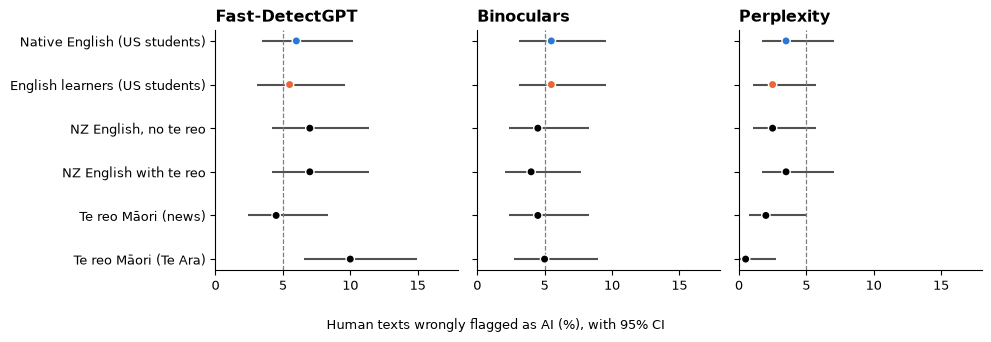

In [5]:
# This cell plots Figure 1, the false positive rate of every human group, one
# panel per detector, with the calibrated 5% rate as a dashed line.
fpr = flag_rates(df, thr[0.05], HUMAN)
fig, axes = plt.subplots(1, 3, figsize=(10, 3.4), sharey=True)
for ax, name in zip(axes, DET.values()):
    r = fpr[fpr.detector == name].iloc[::-1]
    lo, hi = np.array(r.ci.tolist()).T * 100
    ax.hlines(range(len(r)), lo, hi, color=INK)
    ax.scatter(r.rate * 100, range(len(r)), zorder=3, edgecolor="white",
               color=[ORANGE if g == "esl" else BLUE if g == "native" else "black" for g in r.group])
    ax.axvline(5, ls="--", color="grey", lw=0.9)
    ax.set(title=name, yticks=range(len(r)), yticklabels=r.label, xlim=(0, 18))
fig.supxlabel("Human texts wrongly flagged as AI (%), with 95% CI", fontsize=9)
fig.tight_layout(); fig.savefig("../results/figures/fig1_false_positives.png")
display(fpr.pivot(index="label", columns="detector", values="rate").loc[list(HUMAN.values())].round(3))

In [6]:
# This cell runs one-sided Fisher exact tests of English learners against native
# writers, NZ English with te reo against NZ English without it, and the two te
# reo Māori sources against native English essays.
for g, ref in [("esl", "native"), ("nz_web_reo", "nz_web_plain"), ("mi_news", "native"), ("teara_mi", "native")]:
    for d, name in DET.items():
        k = [int((df.loc[df.group == x, f"ai_{d}"] > thr[0.05][d]).sum()) for x in (g, ref)]
        p = stats.fisher_exact([[k[0], 200 - k[0]], [k[1], 200 - k[1]]], alternative="greater")[1]
        print(f"{HUMAN[g]:30s} vs {HUMAN[ref]:28s} {name:15s} {k[0]/2:4.1f}% vs {k[1]/2:4.1f}%  p = {p:.3f}")

English learners (US students) vs Native English (US students) Fast-DetectGPT   5.5% vs  6.0%  p = 0.666
English learners (US students) vs Native English (US students) Binoculars       5.5% vs  5.5%  p = 0.587
English learners (US students) vs Native English (US students) Perplexity       2.5% vs  3.5%  p = 0.810
NZ English with te reo         vs NZ English, no te reo        Fast-DetectGPT   7.0% vs  7.0%  p = 0.577
NZ English with te reo         vs NZ English, no te reo        Binoculars       4.0% vs  4.5%  p = 0.689
NZ English with te reo         vs NZ English, no te reo        Perplexity       3.5% vs  2.5%  p = 0.385
Te reo Māori (news)            vs Native English (US students) Fast-DetectGPT   4.5% vs  6.0%  p = 0.815
Te reo Māori (news)            vs Native English (US students) Binoculars       4.5% vs  5.5%  p = 0.754
Te reo Māori (news)            vs Native English (US students) Perplexity       2.0% vs  3.5%  p = 0.890
Te reo Māori (Te Ara)          vs Native English (US st

## 4. What makes human writing look machine-written?

Nested regressions on all 1,400 human PERSUADE essays. Coefficients are in standard deviations of the AI score; essay score is the 1-6 quality mark given by trained human markers.

In [7]:
# This cell fits the three nested models for each detector and reports how the
# English-learner effect changes once writing quality and vocabulary are added.
pers = pd.concat([S["human_persuade"], S["calibration_native"]], ignore_index=True)
pers["esl"] = (pers.ell_status == "Yes").astype(int)
for c in ["holistic_essay_score", "type_token_ratio", "word_count"]:
    pers[f"z_{c}"] = (pers[c] - pers[c].mean()) / pers[c].std()
rows = []
for d, name in DET.items():
    pers["y"] = (pers[f"ai_{d}"] - pers[f"ai_{d}"].mean()) / pers[f"ai_{d}"].std()
    for f in ["y ~ esl", "y ~ esl + z_holistic_essay_score",
              "y ~ esl + z_holistic_essay_score + z_type_token_ratio + z_word_count"]:
        m = smf.ols(f, data=pers).fit(cov_type="HC3")
        rows.append({"detector": name, "model": f[4:], **m.params.drop("Intercept").round(3), "r2": m.rsquared})
pd.DataFrame(rows).set_index(["detector", "model"])

esl  \
detector       model                                                       
Fast-DetectGPT esl                                                -0.337   
               esl + z_holistic_essay_score                       -0.186   
               esl + z_holistic_essay_score + z_type_token_rat... -0.376   
Binoculars     esl                                                -0.343   
               esl + z_holistic_essay_score                       -0.183   
               esl + z_holistic_essay_score + z_type_token_rat... -0.379   
Perplexity     esl                                                -0.574   
               esl + z_holistic_essay_score                       -0.310   
               esl + z_holistic_essay_score + z_type_token_rat... -0.542   

                                                                         r2  \
detector       model                                                          
Fast-DetectGPT esl                                                 0.013918   
               esl + z_holistic_essay_score                        0.070676   
               esl + z_holistic_essay_score + z_type_token_rat...  0.241997   
Binoculars     esl                                                 0.014427   
               esl + z_holistic_essay_score                        0.077773   
               esl + z_holistic_essay_score + z_type_token_rat...  0.239652   
Perplexity     esl                                                 0.040367   
               esl + z_holistic_essay_score                        0.213903   
               esl + z_holistic_essay_score + z_type_token_rat...  0.459473   

                                                                   z_holistic_essay_score  \
detector       model                                                                        
Fast-DetectGPT esl                                                                    NaN   
               esl + z_holistic_essay_score                                         0.244   
               esl + z_holistic_essay_score + z_type_token_rat...                   0.224   
Binoculars     esl                                                                    NaN   
               esl + z_holistic_essay_score                                         0.258   
               esl + z_holistic_essay_score + z_type_token_rat...                   0.205   
Perplexity     esl                                                                    NaN   
               esl + z_holistic_essay_score                                         0.427   
               esl + z_holistic_essay_score + z_type_token_rat...                   0.388   

                                                                   z_type_token_ratio  \
detector       model                                                                    
Fast-DetectGPT esl                                                                NaN   
               esl + z_holistic_essay_score                                       NaN   
               esl + z_holistic_essay_score + z_type_token_rat...              -0.477   
Binoculars     esl                                                                NaN   
               esl + z_holistic_essay_score                                       NaN   
               esl + z_holistic_essay_score + z_type_token_rat...              -0.467   
Perplexity     esl                                                                NaN   
               esl + z_holistic_essay_score                                       NaN   
               esl + z_holistic_essay_score + z_type_token_rat...              -0.573   

                                                                   z_word_count  
detector       model                                                             
Fast-DetectGPT esl                                                          NaN  
               esl + z_holistic_essay_score                                 NaN  
               esl + z_holisti

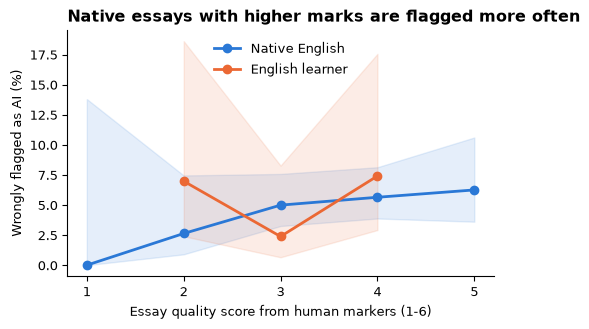

In [8]:
# This cell plots Figure 2, the Fast-DetectGPT flag rate at each essay score,
# for native writers and English learners (points with at least 20 essays).
pers["flag"] = pers.ai_fast_detect_gpt > thr[0.05]["fast_detect_gpt"]
fig, ax = plt.subplots(figsize=(5.5, 3.2))
for esl, label, col in ((0, "Native English", BLUE), (1, "English learner", ORANGE)):
    g = pers[pers.esl == esl].groupby("holistic_essay_score").flag.agg(["sum", "count"]).query("count >= 20")
    ci = np.array([wilson(k, n) for k, n in g.values]) * 100
    ax.plot(g.index, g["sum"] / g["count"] * 100, marker="o", color=col, lw=2, label=label)
    ax.fill_between(g.index, ci[:, 0], ci[:, 1], color=col, alpha=0.12)
ax.set(xlabel="Essay quality score from human markers (1-6)", ylabel="Wrongly flagged as AI (%)",
       title="Native essays with higher marks are flagged more often", xticks=range(1, 6))
ax.legend(frameon=False)
fig.savefig("../results/figures/fig2_flag_by_essay_score.png", bbox_inches="tight")

## 5. The grey zone: AI grammar fixes

The same human essays before and after an AI corrected only their spelling and grammar, which most university policies allow. *Newly flagged* counts innocent essays that cross the threshold only after the fix (exact McNemar test).

In [9]:
# This cell compares each grammar-fixed essay with its own original version.
human = df[df.group.isin(["esl", "native"])].set_index("essay_id")
rows = []
for g in ["frontier_polish_esl", "frontier_polish_native"]:
    p = df[df.group == g]
    for d, name in DET.items():
        before = human.loc[p.source_essay_id, f"ai_{d}"].values > thr[0.05][d]
        after = p[f"ai_{d}"].values > thr[0.05][d]
        new, cleared = int((~before & after).sum()), int((before & ~after).sum())
        rows.append({"group": AI[g], "detector": name, "n": len(p), "flagged_before": before.mean(),
                     "flagged_after": after.mean(), "newly_flagged": new, "cleared": cleared,
                     "p": stats.binomtest(new, new + cleared, alternative="greater").pvalue if new + cleared else 1})
polish = pd.DataFrame(rows)
polish.round(3)

,group,detector,n,flagged_before,flagged_after,newly_flagged,cleared,p
0,Grammar-fixed ESL essay,Fast-DetectGPT,20,0.0,0.15,3,0,0.125
1,Grammar-fixed ESL essay,Binoculars,20,0.0,0.25,5,0,0.031
2,Grammar-fixed ESL essay,Perplexity,20,0.0,0.20,4,0,0.062
3,Grammar-fixed native essay,Fast-DetectGPT,10,0.2,0.40,2,0,0.250
4,Grammar-fixed native essay,Binoculars,10,0.2,0.50,3,0,0.125
5,Grammar-fixed native essay,Perplexity,10,0.0,0.40,4,0,0.062


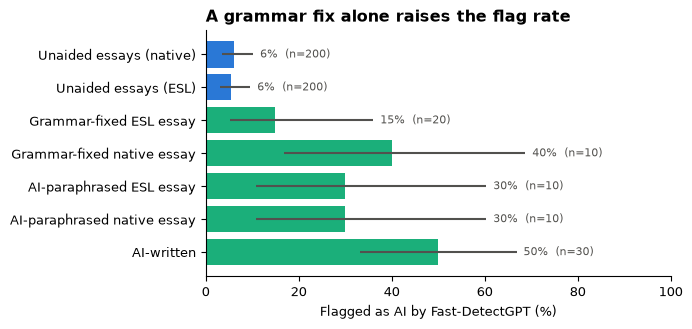

In [10]:
# This cell plots Figure 3, showing how often each kind of text is flagged by
# Fast-DetectGPT, from unaided human writing through to fully AI-written.
order = {"native": "Unaided essays (native)", "esl": "Unaided essays (ESL)", **{g: AI[g] for g in (
    "frontier_polish_esl", "frontier_polish_native", "frontier_paraphrase_esl", "frontier_paraphrase_native", "frontier_generate")}}
r = flag_rates(df, thr[0.05], order).query("detector == 'Fast-DetectGPT'").iloc[::-1]
fig, ax = plt.subplots(figsize=(6, 3.2))
ax.barh(r.label, r.rate * 100, color=[BLUE if "Unaided" in l else AQUA for l in r.label])
lo, hi = np.array(r.ci.tolist()).T * 100
ax.hlines(r.label, lo, hi, color=INK)
for y, (rate, n) in enumerate(zip(r.rate, r.n)):
    ax.text(hi[y] + 1.5, y, f"{rate:.0%}  (n={n})", va="center", fontsize=8, color=INK)
ax.set(xlim=(0, 100), xlabel="Flagged as AI by Fast-DetectGPT (%)", title="A grammar fix alone raises the flag rate")
fig.savefig("../results/figures/fig3_grey_zone.png", bbox_inches="tight")

## 6. Te reo Māori

The controlled swap experiment: the change in each essay's AI score when kupu Māori, or rare English words, replace common English words. Essays where any version hit the 512-token limit are excluded, because te reo uses more tokens per word and truncation would confound the comparison.

In [11]:
# This cell runs the paired swap test (Wilcoxon signed-rank) on human essays and
# on AI-written essays. A positive change means the essay looks MORE machine-like.
rows = []
for name_set, v in (("human essays", S["reo_human"]), ("AI-written essays", S["reo_frontier"])):
    v = v[v.essay_id.isin(v.groupby("essay_id").n_tokens.max().loc[lambda s: s < 511].index)]
    for d, name in DET.items():
        w = v.pivot_table(index="essay_id", columns="condition", values=f"ai_{d}")
        for a, b in [("reo_full", "original"), ("rare_english", "original"), ("reo_full", "rare_english")]:
            diff = w[a] - w[b]
            rows.append({"texts": name_set, "detector": name, "contrast": f"{a} - {b}", "n": len(diff),
                         "median_change": diff.median(), "p": stats.wilcoxon(diff).pvalue})
pd.DataFrame(rows).round(4)

,texts,detector,contrast,n,median_change,p
0,human essays,Fast-DetectGPT,reo_full - original,136,-0.0779,0.1306
1,human essays,Fast-DetectGPT,rare_english - original,136,-0.1391,0.0035
2,human essays,Fast-DetectGPT,reo_full - rare_english,136,0.0511,0.1910
3,human essays,Binoculars,reo_full - original,136,-0.0013,0.2408
4,human essays,Binoculars,rare_english - original,136,-0.0039,0.0099
5,human essays,Binoculars,reo_full - rare_english,136,0.0022,0.3697
6,human essays,Perplexity,reo_full - original,136,-0.0459,0.0032
7,human essays,Perplexity,rare_english - original,136,-0.1399,0.0000
8,human essays,Perplexity,reo_full - rare_english,136,0.1155,0.0000
9,AI-written essays,Fast-DetectGPT,reo_full - original,12,-0.5522,0.0093


## 7. What does a flag mean? The chance a flagged student is innocent

Bayes' rule: P(innocent | flagged) = FPR(1-π) / (FPR(1-π) + TPR·π), where π is the share of submissions that really used AI, FPR comes from the human essays and TPR from the AI-written essays (Fast-DetectGPT, 5% threshold).

{'5% using AI': '69% / 90% innocent', '10% using AI': '51% / 81% innocent', '20% using AI': '32% / 65% innocent'}


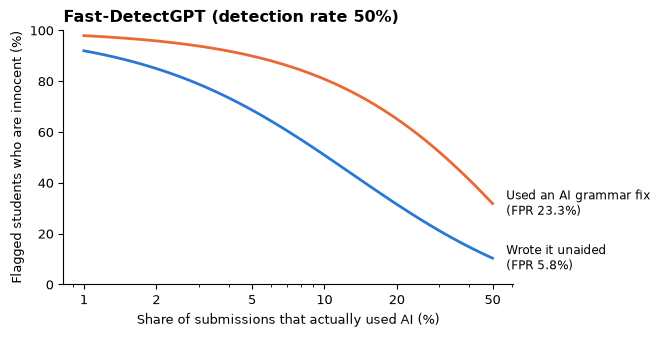

In [12]:
# This cell plots Figure 4, comparing students who wrote unaided with students
# who used a permitted AI grammar fix.
tpr = (ai.ai_fast_detect_gpt > thr[0.05]["fast_detect_gpt"]).mean()
f_plain = fpr.query("detector == 'Fast-DetectGPT' and group in ['native', 'esl']").flagged.sum() / 400
innocent = lambda f, p: f * (1 - p) / (f * (1 - p) + tpr * p)
f_fix = polish.query("detector == 'Fast-DetectGPT'").eval("flagged_after * n").sum() / 30
pi = np.geomspace(0.01, 0.5, 60)
fig, ax = plt.subplots(figsize=(5.8, 3.3))
for f, label, col in ((f_plain, "Wrote it unaided", BLUE), (f_fix, "Used an AI grammar fix", ORANGE)):
    y = innocent(f, pi) * 100
    ax.plot(pi * 100, y, color=col, lw=2)
    ax.text(57, y[-1], f"{label}\n(FPR {f:.1%})", va="center", fontsize=8.5)
ax.set(xscale="log", ylim=(0, 100), xlabel="Share of submissions that actually used AI (%)",
       ylabel="Flagged students who are innocent (%)", title=f"Fast-DetectGPT (detection rate {tpr:.0%})")
ax.set_xticks([1, 2, 5, 10, 20, 50], ["1", "2", "5", "10", "20", "50"])
fig.savefig("../results/figures/fig4_p_innocent.png", bbox_inches="tight")
print({f"{p:.0%} using AI": f"{innocent(f_plain, p):.0%} / {innocent(f_fix, p):.0%} innocent" for p in (0.05, 0.10, 0.20)})